# 1단계 기술통계: K리그 관중은 언제, 어디서 많았나

- 데이터: `data/processed/features.csv` (제외 경기 14개는 뺀다)
- 그림은 `reports/figures/`에 저장한다.
- **조건별 비교는 '같은 구단·같은 시즌 평균 대비 %'로 본다.** 평균 관중을 그대로 비교하면 관중이 많은 구단(서울, 울산 등)의 경기가 많은 조건이 유리하게 나오기 때문이다. 이것도 다른 요인을 통제한 값은 아니므로, 요인별 효과는 회귀 모형(`02_models.ipynb`)에서 본다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(ROOT / "data" / "processed" / "features.csv", encoding="utf-8-sig", parse_dates=["date"])
df = raw[raw["excluded"] == 0].copy()
print(f"분석 경기 {len(df)} (제외 {raw['excluded'].sum()})")

# 그림 스타일: 옅은 격자·축, 텍스트는 검정/회색, 리그 색은 고정 (K리그1 파랑, K리그2 주황)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
LEAGUE_COLOR = {"K리그1": "#2a78d6", "K리그2": "#eb6834"}
plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 200,
})

분석 경기 1849 (제외 14)


## 1. 시즌·리그별 경기 수와 관중

In [2]:
summary = (df.groupby(["season", "league"])
             .agg(경기수=("match_id", "size"), 평균관중=("attendance", "mean"),
                  중앙값=("attendance", "median"), 최다=("attendance", "max"))
             .round(0).astype(int))
summary

경기수   평균관중   중앙값     최다
season league                         
2023   K리그1    228  10733  9059  45007
       K리그2    232   2358  2018  13340
2024   K리그1    227  10992  9513  52600
       K리그2    227   3636  2750  14866
2025   K리그1    228  10081  8502  48008
       K리그2    272   4297  2780  22625
2026   K리그1    196   8840  7498  35729
       K리그2    239   4435  2765  24071

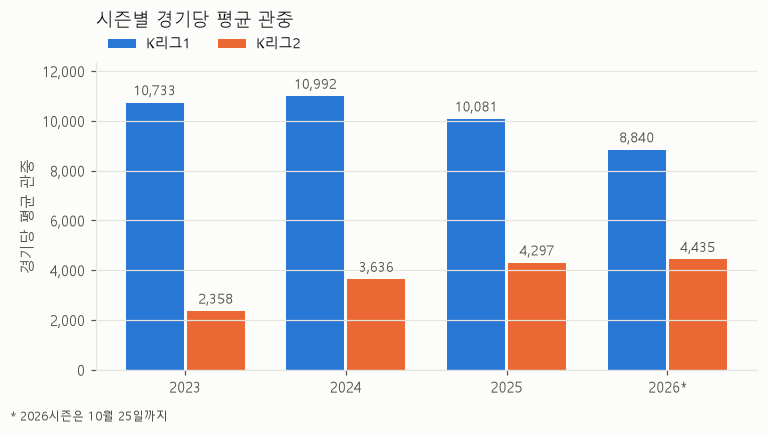

In [3]:
pivot = df.groupby(["season", "league"])["attendance"].mean().unstack()
x = np.arange(len(pivot.index)); w = 0.38
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, lg in enumerate(pivot.columns):
    bars = ax.bar(x + (i - 0.5) * w, pivot[lg], width=w - 0.02, color=LEAGUE_COLOR[lg], label=lg)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in pivot[lg]], padding=3, fontsize=9, color=INK2)
ax.set_xticks(x, [f"{s}" + ("*" if s == 2026 else "") for s in pivot.index])
ax.set_ylabel("경기당 평균 관중")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, pivot.max().max() * 1.12)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
ax.set_title("시즌별 경기당 평균 관중", loc="left", fontsize=12, pad=24)
fig.text(0.01, -0.02, "* 2026시즌은 10월 25일까지", fontsize=8, color=INK2)
fig.tight_layout(); fig.savefig(FIG / "01_season_league.png", bbox_inches="tight"); plt.show()

## 2. 구단별 평균 관중 (2023~2026, 홈경기 기준)

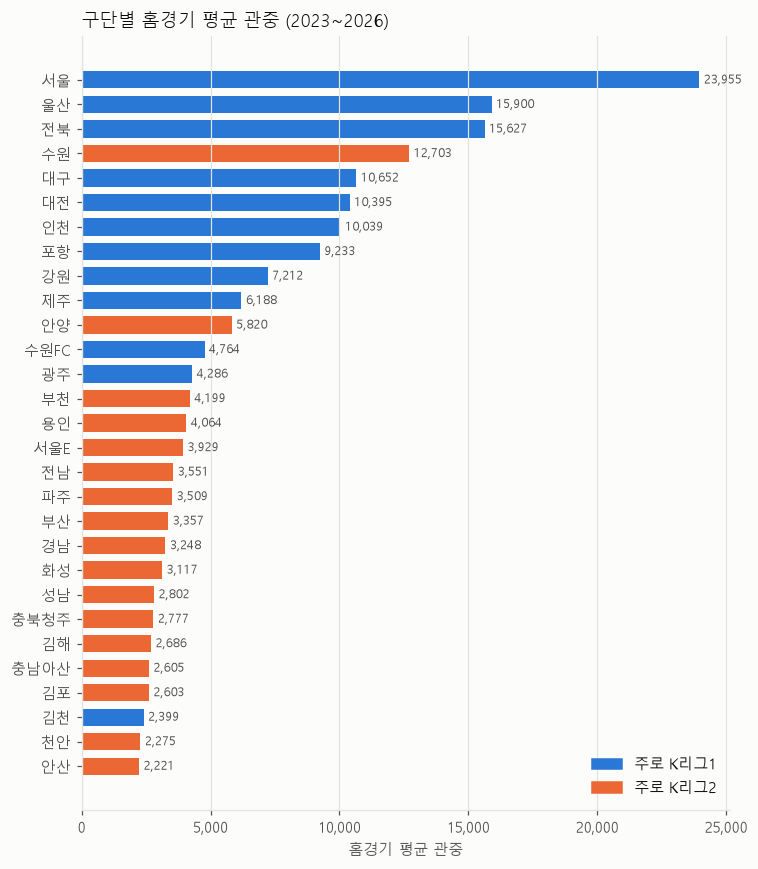

,평균관중,경기수,리그
home_team,,,
서울,23955.0,72,K리그1
울산,15900.0,73,K리그1
전북,15627.0,74,K리그1
수원,12703.0,64,K리그2
대구,10652.0,70,K리그1
대전,10395.0,74,K리그1
인천,10039.0,74,K리그1
포항,9233.0,70,K리그1
강원,7212.0,74,K리그1


In [4]:
club = (df.groupby("home_team")
          .agg(평균관중=("attendance", "mean"), 경기수=("match_id", "size"),
               리그=("league", lambda s: s.value_counts().idxmax()))
          .sort_values("평균관중"))
fig, ax = plt.subplots(figsize=(7, 8))
bars = ax.barh(club.index, club["평균관중"], color=[LEAGUE_COLOR[l] for l in club["리그"]], height=0.7)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in club["평균관중"]], padding=3, fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
ax.set_xlabel("홈경기 평균 관중")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in LEAGUE_COLOR.values()]
ax.legend(handles, ["주로 K리그1", "주로 K리그2"], frameon=False, loc="lower right")
ax.set_title("구단별 홈경기 평균 관중 (2023~2026)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "02_club.png", bbox_inches="tight"); plt.show()
club.sort_values("평균관중", ascending=False).round(0)

## 3. 조건별로 관중이 얼마나 달랐나 (같은 구단·시즌 평균 대비)

각 경기의 log(관중)에서 그 구단·그 시즌의 평균을 뺀 값을 조건별로 평균 내고, `(e^x − 1) × 100`으로 %로 바꾼다.
예: '+10%'는 같은 구단의 같은 시즌 다른 경기보다 관중이 평균 10% 많았다는 뜻이다.

In [5]:
df["dev"] = df["ln_attendance"] - df.groupby(["home_team", "season"])["ln_attendance"].transform("mean")

def pct_gap(mask, base):
    """조건(mask)인 경기와 기준(base) 경기의 '구단·시즌 평균 대비' 차이(%)"""
    return (np.exp(df.loc[mask, "dev"].mean() - df.loc[base, "dev"].mean()) - 1) * 100

weekday = df["day_type"] == "평일"
rows = [
    ("주말 (평일 대비)", pct_gap(df["day_type"] == "주말", weekday), (df["day_type"] == "주말").sum()),
    ("평일 공휴일 (평일 대비)", pct_gap(df["day_type"] == "평일공휴일", weekday), (df["day_type"] == "평일공휴일").sum()),
    ("주말·공휴일 저녁 (같은 날 유형의 낮 대비)", pct_gap((df["night"] == 1) & ~weekday, (df["night"] == 0) & ~weekday),
     ((df["night"] == 1) & ~weekday).sum()),
    ("경기 시간 비 1mm 이상", pct_gap(df["rain"] == 1, df["rain"] == 0), (df["rain"] == 1).sum()),
    ("킥오프 30℃ 이상", pct_gap(df["hot"] == 1, df["hot"] == 0), (df["hot"] == 1).sum()),
    ("킥오프 5℃ 이하", pct_gap(df["cold"] == 1, df["cold"] == 0), (df["cold"] == 1).sum()),
    ("더비", pct_gap(df["derby"] == 1, df["derby"] == 0), (df["derby"] == 1).sum()),
    ("시즌 첫 홈경기", pct_gap(df["home_opener"] == 1, df["home_opener"] == 0), (df["home_opener"] == 1).sum()),
    ("시즌 마지막 홈경기 (2023~2025)", pct_gap(df["last_home"] == 1, (df["last_home"] == 0) & (df["season"] < 2026)),
     (df["last_home"] == 1).sum()),
]
gap = pd.DataFrame(rows, columns=["조건", "차이(%)", "경기 수"]).set_index("조건").round(1)
gap

,차이(%),경기 수
조건,,
주말 (평일 대비),61.4,1525
평일 공휴일 (평일 대비),71.4,80
주말·공휴일 저녁 (같은 날 유형의 낮 대비),-10.1,678
경기 시간 비 1mm 이상,-25.9,165
킥오프 30℃ 이상,-1.6,144
킥오프 5℃ 이하,25.5,34
더비,60.9,57
시즌 첫 홈경기,70.3,105
시즌 마지막 홈경기 (2023~2025),32.7,75


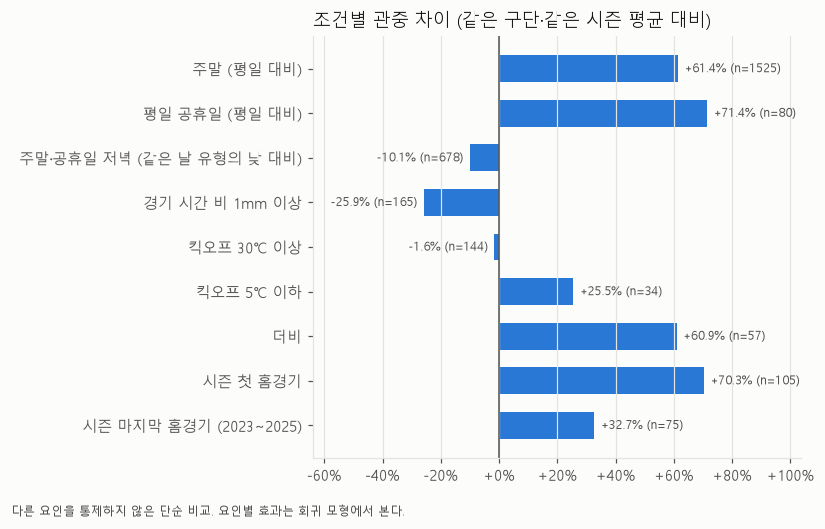

In [6]:
g = gap.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
bars = ax.barh(g.index, g["차이(%)"], color="#2a78d6", height=0.6)
ax.bar_label(bars, labels=[f"{v:+.1f}% (n={n})" for v, n in zip(g["차이(%)"], g["경기 수"])],
             padding=4, fontsize=8, color=INK2)
ax.axvline(0, color=INK2, linewidth=1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
ax.grid(axis="y", visible=False)
lo, hi = g["차이(%)"].min(), g["차이(%)"].max()
ax.set_xlim(min(lo, 0) - 38, hi * 1.45)
ax.set_title("조건별 관중 차이 (같은 구단·같은 시즌 평균 대비)", loc="left", fontsize=12)
fig.text(0.01, -0.03, "다른 요인을 통제하지 않은 단순 비교. 요인별 효과는 회귀 모형에서 본다.", fontsize=8, color=INK2)
fig.tight_layout(); fig.savefig(FIG / "03_condition_gap.png", bbox_inches="tight"); plt.show()

## 4. 킥오프 시간 분포

In [7]:
pd.crosstab(df["day_type"], df["kickoff_hour"].map(lambda h: "낮(~15시)" if h < 16 else ("오후(16~17시)" if h < 18 else "저녁(18시~)")),
            margins=True, margins_name="합계")

kickoff_hour,낮(~15시),오후(16~17시),저녁(18시~),합계
day_type,,,,
주말,384,482,659,1525
평일,0,0,244,244
평일공휴일,29,32,19,80
합계,413,514,922,1849


## 5. 날씨: 경기 시간대 vs 하루 전체

하루 중 비가 왔어도 경기 시간에는 오지 않은 경우가 많다. 그래서 본 분석은 경기 시간대 기준(`rain`, `hot`, `cold`)을 쓴다.

In [8]:
for t, d, name in [("rain", "rain_day", "비"), ("hot", "hot_day", "더위"), ("cold", "cold_day", "추위")]:
    print(f"[{name}] 행 = 하루 기준({d}), 열 = 경기 시간대 기준({t})")
    print(pd.crosstab(df[d], df[t], margins=True, margins_name="합계"))
    print()

[비] 행 = 하루 기준(rain_day), 열 = 경기 시간대 기준(rain)
rain         0    1    합계
rain_day                 
0         1369    0  1369
1          315  165   480
합계        1684  165  1849

[더위] 행 = 하루 기준(hot_day), 열 = 경기 시간대 기준(hot)
hot         0    1    합계
hot_day                 
0        1644   31  1675
1          61  113   174
합계       1705  144  1849

[추위] 행 = 하루 기준(cold_day), 열 = 경기 시간대 기준(cold)
cold         0   1    합계
cold_day                
0         1748   5  1753
1           67  29    96
합계        1815  34  1849



## 6. 상대팀 원정 팬 동원력 (직전 5번 원정 평균, 원정석이 꽉 찬 경기는 제외)

In [9]:
(df.groupby("away_team")["away_fans_pre"].mean().sort_values(ascending=False).round(0)
   .rename("평균 원정 관중(경기 전 값)").to_frame().head(10))

,평균 원정 관중(경기 전 값)
away_team,
수원,2849.0
전북,2102.0
울산,1634.0
서울,1314.0
인천,1288.0
대구,1255.0
대전,985.0
포항,956.0
안양,732.0
